# NumCompute-Stream demo
A decision tree trained on a data stream with **buffered retraining**.

Steps: load a CSV with `io.py` → split it into chunks → train a pipeline with `.partial_fit()` chunk by chunk (test-then-train) → log and visualise the metrics.

Data: `stream_data.csv`, a synthetic 3-class stream (6,000 rows, 5 features, ~2% missing values, 5% label noise) with an abrupt **concept drift at row 3,000** (generated by `numcompute_stream.benchmarking.make_drift_stream`).

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))   # make the package importable from demo/

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import numcompute_stream as ns
from numcompute_stream import visualise as vis

## 1. Load the CSV with `io.py`
Empty cells become NaN, and rows without a label are dropped.

In [2]:
X, y, feature_names = ns.load_csv_xy('stream_data.csv', target_column='label')
print('X shape:', X.shape, '| y shape:', y.shape)
print('features:', feature_names)
print('missing values per feature:', np.isnan(X).sum(axis=0))
print('class counts:', dict(zip(*np.unique(y, return_counts=True))))

X shape: (6000, 5) | y shape: (6000,)
features: ['f1', 'f2', 'f3', 'f4', 'f5']
missing values per feature: [135 128 112 107  95]
class counts: {np.int64(0): np.int64(1459), np.int64(1): np.int64(2941), np.int64(2): np.int64(1600)}


`stream_csv` reads the same file lazily, one chunk at a time, without loading it all:

In [3]:
first_X, first_y = next(ns.stream_csv('stream_data.csv', chunk_size=100))
print('first chunk from disk:', first_X.shape, first_y.shape)

first chunk from disk: (100, 5) (100,)


## 2. Split the data into chunks to simulate a stream

In [4]:
CHUNK_SIZE = 100
chunks = list(ns.iter_chunks(X, y, chunk_size=CHUNK_SIZE))
print(f'{len(chunks)} chunks of {CHUNK_SIZE} rows (drift at chunk {3000 // CHUNK_SIZE})')

60 chunks of 100 rows (drift at chunk 30)


## 3. Train the pipeline incrementally with `.partial_fit()`
Pipeline: `SimpleImputer` → `StandardScaler` → `DecisionTreeClassifier(max_depth=5, buffer_size=500)`.

`StreamTrainer` scores each chunk **before** training on it, so every accuracy is measured on unseen data. The tree buffers chunks and retrains once 500 samples are waiting; until the first retrain there is no model, so the first chunks show `n/a`.

In [5]:
pipe = ns.Pipeline([
    ('impute', ns.SimpleImputer(strategy='mean')),
    ('scale', ns.StandardScaler()),
    ('model', ns.DecisionTreeClassifier(max_depth=5, buffer_size=500)),
])
trainer = ns.StreamTrainer(
    pipe,
    metrics={'macro_f1': ns.StreamingF1(average='macro'),
             'macro_precision': ns.StreamingPrecision(average='macro')},
    window=5, verbose=True)

for X_chunk, y_chunk in chunks:
    trainer.step(X_chunk, y_chunk)    # score, then partial_fit

chunk   0 | n= 100 | acc   n/a  | cum   n/a  | roll   n/a  | buffer 100 | mem     5.1 KB | fit   0.53 ms
chunk   1 | n= 100 | acc   n/a  | cum   n/a  | roll   n/a  | buffer 200 | mem     9.8 KB | fit   0.30 ms
chunk   2 | n= 100 | acc   n/a  | cum   n/a  | roll   n/a  | buffer 300 | mem    14.5 KB | fit   0.28 ms
chunk   3 | n= 100 | acc   n/a  | cum   n/a  | roll   n/a  | buffer 400 | mem    19.2 KB | fit   0.23 ms
chunk   4 | n= 100 | acc   n/a  | cum   n/a  | roll   n/a  | buffer 0 | mem     3.4 KB | fit   5.73 ms retrained
chunk   5 | n= 100 | acc  87.0% | cum  87.0% | roll  87.0% | buffer 100 | mem     8.1 KB | fit   0.32 ms
chunk   6 | n= 100 | acc  90.0% | cum  88.5% | roll  88.5% | buffer 200 | mem    12.8 KB | fit   0.32 ms
chunk   7 | n= 100 | acc  90.0% | cum  89.0% | roll  89.0% | buffer 300 | mem    17.5 KB | fit   0.36 ms
chunk   8 | n= 100 | acc  92.0% | cum  89.8% | roll  89.8% | buffer 400 | mem    22.2 KB | fit   0.37 ms
chunk   9 | n= 100 | acc  88.0% | cum  89.4% | 

In [6]:
summary = trainer.summary()
for key, value in summary.items():
    print(f'{key:20s} {value:.4f}' if isinstance(value, float) else f'{key:20s} {value}')

chunks               60
samples              6000
cumulative_accuracy  0.8751
total_fit_time       0.0712
n_retrains           12
macro_f1             0.8679
macro_precision      0.8691


## 4. Metrics over time
Dotted lines mark retrains. Accuracy drops at the drift (chunk 30) and recovers after the next retrain, once the buffer holds data from the new concept.

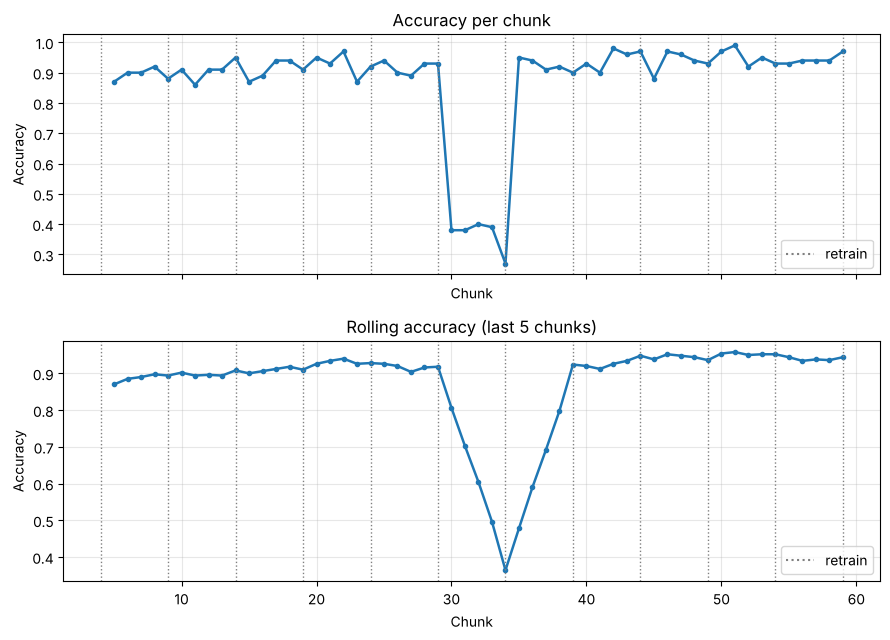

In [7]:
retrains = np.flatnonzero([r['retrained'] for r in trainer.log_])
fig, axes = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True)
vis.plot_metric_over_time(trainer.history('chunk_accuracy'), 'Accuracy per chunk',
                          'Accuracy', ax=axes[0], marks=retrains)
vis.plot_metric_over_time(trainer.history('rolling_accuracy'), 'Rolling accuracy (last 5 chunks)',
                          'Accuracy', ax=axes[1], marks=retrains)
fig.tight_layout()

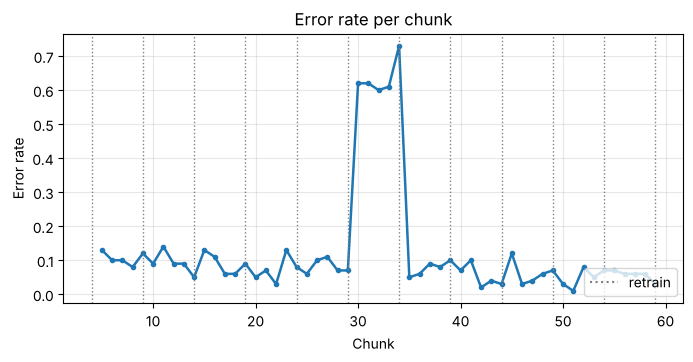

In [8]:
vis.plot_metric_over_time(1 - trainer.history('chunk_accuracy'), 'Error rate per chunk',
                          'Error rate', marks=retrains);

## 5. Predictions vs ground truth on the latest chunk

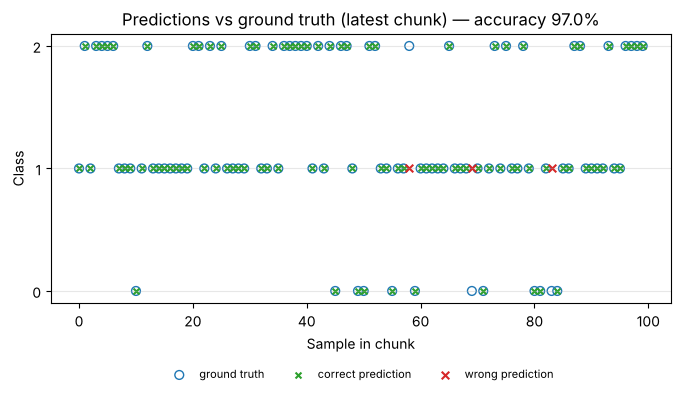

In [9]:
y_last, pred_last = trainer.last_predictions_
vis.plot_predictions_vs_ground_truth(y_last, pred_last);

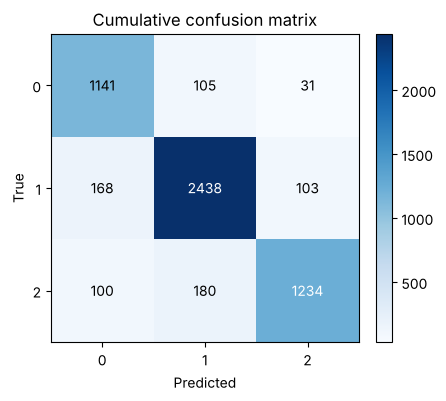

In [10]:
cm, labels = trainer.metrics['macro_f1'].cm_.result()
vis.plot_confusion_matrix(cm, labels, title='Cumulative confusion matrix');

## 6. Model comparison: `buffer_size=100` vs `buffer_size=2000`
A small buffer retrains often and adapts to the drift quickly; a large buffer trains on more data but reacts late, and its retrain after the drift mixes old and new concepts.

buffer_size=  100: cumulative accuracy 0.884, retrains 60, total retrain time 121.6 ms
buffer_size= 2000: cumulative accuracy 0.634, retrains 3, total retrain time 57.5 ms


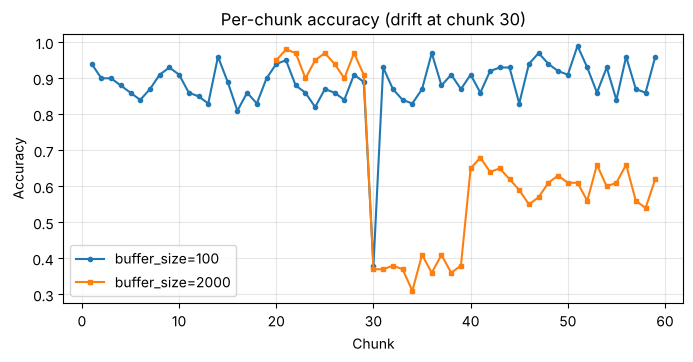

In [11]:
results = {}
for b in (100, 2000):
    tree = ns.DecisionTreeClassifier(max_depth=5, buffer_size=b)
    t = ns.StreamTrainer(tree).run(ns.iter_chunks(X, y, CHUNK_SIZE))
    results[b] = t
    print(f'buffer_size={b:5d}: cumulative accuracy {t.cumulative_accuracy_.result():.3f}, '
          f'retrains {tree.n_retrains_}, total retrain time {tree.total_retrain_time_ * 1000:.1f} ms')

vis.compare_models(results[100].history('chunk_accuracy'), results[2000].history('chunk_accuracy'),
                   labels=('buffer_size=100', 'buffer_size=2000'),
                   title='Per-chunk accuracy (drift at chunk 30)');

## 7. Streaming statistics with `update_stats`

In [12]:
state = None
for X_chunk, _ in chunks:
    state = ns.update_stats(X_chunk, state, reservoir_size=1000, random_state=0)
print('streaming mean:', np.round(state.mean(), 4))
print('np.nanmean    :', np.round(np.nanmean(X, axis=0), 4))
print('streaming var :', np.round(state.var(), 4))
print('median (reservoir estimate):', np.round(state.quantile(0.5), 3))

streaming mean: [-0.014   0.0083  0.005   0.0195  0.0184]
np.nanmean    : [-0.014   0.0083  0.005   0.0195  0.0184]
streaming var : [1.0277 1.0078 0.9746 1.0281 1.0064]
median (reservoir estimate): [0.015 0.036 0.056 0.043 0.1  ]


## 8. The latest tree

In [13]:
tree = pipe.named_steps['model']
print(f'depth {tree.get_depth()}, leaves {tree.get_n_leaves()}, retrains {tree.n_retrains_}')
print(tree.export_text(feature_names=feature_names))

depth 5, leaves 21, retrains 12
|--- f3 <= -0.004
|   |--- f4 <= -0.5
|   |   |--- f3 <= -0.009
|   |   |   |--- f2 <= -0.794
|   |   |   |   |--- f2 <= -0.862
|   |   |   |   |   |--- class: 0 (n=19)
|   |   |   |   |--- f2 >  -0.862
|   |   |   |   |   |--- class: 1 (n=2)
|   |   |   |--- f2 >  -0.794
|   |   |   |   |--- class: 0 (n=59)
|   |   |--- f3 >  -0.009
|   |   |   |--- class: 1 (n=1)
|   |--- f4 >  -0.5
|   |   |--- f2 <= -1.907
|   |   |   |--- f2 <= -2.192
|   |   |   |   |--- class: 1 (n=2)
|   |   |   |--- f2 >  -2.192
|   |   |   |   |--- class: 2 (n=1)
|   |   |--- f2 >  -1.907
|   |   |   |--- f4 <= -0.458
|   |   |   |   |--- f1 <= 0.971
|   |   |   |   |   |--- class: 1 (n=3)
|   |   |   |   |--- f1 >  0.971
|   |   |   |   |   |--- class: 2 (n=1)
|   |   |   |--- f4 >  -0.458
|   |   |   |   |--- f2 <= -0.013
|   |   |   |   |   |--- class: 1 (n=69)
|   |   |   |   |--- f2 >  -0.013
|   |   |   |   |   |--- class: 1 (n=90)
|--- f3 >  -0.004
|   |--- f4 <= -0.51
|